# Лабораторна робота 2. Завдання 5 — fine-tuning (AID, варіант 3)

Беремо кращу за **validation** модель із завдань 3–4 (ResNet18 із замороженою основою), **розморожуємо останній
згортковий блок** (`layer4`) і продовжуємо навчання з **меншим learning rate**. Порівнюємо результати до та після
донавчання — загалом і **для кожного класу** (precision, recall, F1, accuracy).

Дані, поділ (15 val + 20 test з кожного класу), кешування, аугментація і цикл навчання — ті самі, що в
`Lab2_AID_steps3_4.ipynb`. Ваги моделей exp3/exp4 беруться з виходу кернела `lab2-aid-steps3-4`
(на Kaggle підключено як input, локально — `steps3_4/out`).

## 0. Налаштування

In [1]:
import os, json, time, random, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.transforms.v2 import functional as TF
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

SEED = 42
IMG_SIZE = 224                 # стандартний вхід для моделей, навчених на ImageNet
BATCH_SIZE = 64
EPOCHS_FT = 15                 # епохи донавчання
LR_FT = 1e-4                   # у 10 разів менший, ніж у exp3/exp4 (1e-3)
WEIGHT_DECAY = 1e-4
BLUR_SIGMA = (0.5, 1.2)        # «легке» розмиття: sigma гаусового ядра 5×5
NUM_WORKERS = min(4, os.cpu_count())
MP_CONTEXT = 'fork' if NUM_WORKERS > 0 else None   # воркери бачать кеш зображень у RAM без копіювання

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
OUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
print('outputs ->', OUT_DIR)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

device: cuda Tesla T4
outputs -> /kaggle/working


## 1. Дані та поділ (як у завданнях 3–4)

In [2]:
VAL_TEST = {   # клас: ([номери файлів val], [номери файлів test])
    'Airport': ([20, 22, 23, 54, 125, 154, 202, 236, 238, 244, 256, 294, 297, 306, 309],
               [1, 29, 38, 46, 47, 85, 91, 97, 190, 206, 223, 231, 234, 251, 262, 278, 311, 314, 329, 345]),
    'BareLand': ([57, 58, 73, 96, 98, 104, 112, 154, 181, 205, 232, 236, 245, 273, 303],
                [2, 5, 40, 60, 62, 63, 77, 109, 115, 120, 146, 163, 167, 187, 192, 217, 221, 231, 267, 282]),
    'BaseballField': ([3, 13, 14, 36, 74, 86, 98, 132, 135, 145, 149, 153, 180, 183, 197],
                     [10, 26, 40, 53, 55, 58, 80, 119, 129, 131, 147, 173, 175, 178, 187, 188, 198, 205, 211, 217]),
    'Beach': ([11, 28, 43, 93, 107, 126, 136, 180, 269, 274, 286, 293, 321, 341, 381],
             [3, 64, 72, 77, 128, 134, 142, 153, 161, 171, 175, 246, 275, 279, 280, 292, 310, 313, 316, 333]),
    'Bridge': ([64, 66, 90, 124, 135, 141, 161, 168, 207, 210, 211, 216, 225, 275, 350],
              [33, 35, 40, 49, 52, 55, 74, 139, 150, 151, 159, 181, 192, 198, 247, 256, 301, 338, 340, 352]),
    'Center': ([35, 47, 55, 62, 79, 83, 156, 158, 170, 171, 208, 222, 228, 239, 240],
              [11, 14, 21, 37, 53, 61, 103, 106, 164, 168, 174, 182, 202, 204, 214, 218, 223, 232, 235, 251]),
    'Church': ([26, 47, 49, 71, 80, 82, 97, 114, 117, 125, 160, 187, 203, 209, 233],
              [3, 7, 9, 20, 28, 51, 53, 58, 63, 70, 74, 78, 99, 151, 175, 197, 199, 234, 237, 240]),
    'Commercial': ([9, 29, 106, 116, 133, 168, 182, 211, 218, 231, 282, 287, 318, 349, 350],
                  [2, 21, 33, 87, 122, 124, 130, 132, 140, 162, 185, 201, 223, 235, 255, 273, 307, 322, 332, 342]),
    'DenseResidential': ([8, 19, 29, 41, 66, 88, 153, 172, 263, 265, 275, 318, 332, 365, 399],
                        [10, 46, 54, 57, 60, 63, 68, 76, 83, 100, 110, 111, 113, 188, 190, 197, 249, 259, 294, 335]),
    'Desert': ([12, 35, 71, 98, 126, 202, 223, 237, 243, 244, 270, 283, 290, 293, 299],
              [23, 44, 54, 64, 69, 73, 90, 121, 138, 144, 152, 185, 186, 231, 255, 256, 266, 279, 289, 292]),
    'Farmland': ([86, 114, 123, 188, 192, 194, 199, 213, 221, 228, 232, 271, 341, 352, 355],
                [3, 21, 43, 100, 155, 195, 201, 208, 215, 217, 220, 226, 236, 253, 270, 273, 290, 320, 329, 336]),
    'Forest': ([3, 22, 37, 40, 70, 75, 112, 114, 141, 149, 197, 198, 221, 224, 235],
              [1, 4, 10, 23, 26, 29, 56, 58, 87, 101, 130, 131, 137, 161, 163, 168, 172, 185, 200, 213]),
    'Industrial': ([19, 23, 55, 56, 117, 128, 131, 138, 145, 151, 232, 279, 293, 350, 376],
                  [11, 13, 24, 25, 32, 48, 62, 64, 92, 123, 130, 143, 178, 217, 225, 228, 303, 308, 309, 330]),
    'Meadow': ([3, 15, 30, 32, 102, 115, 116, 136, 154, 166, 204, 208, 210, 217, 231],
              [2, 27, 45, 46, 49, 93, 105, 119, 122, 126, 129, 147, 193, 197, 198, 211, 241, 251, 257, 273]),
    'MediumResidential': ([4, 6, 14, 19, 37, 67, 75, 116, 119, 125, 180, 182, 188, 238, 249],
                         [1, 3, 5, 8, 11, 13, 15, 22, 24, 29, 109, 114, 130, 163, 202, 205, 207, 210, 284, 289]),
    'Mountain': ([6, 12, 22, 29, 40, 50, 70, 91, 117, 132, 145, 175, 206, 239, 310],
                [11, 16, 20, 24, 51, 54, 98, 101, 119, 137, 142, 146, 154, 166, 185, 190, 218, 225, 237, 336]),
    'Park': ([3, 7, 32, 39, 82, 126, 127, 176, 192, 249, 256, 269, 284, 304, 322],
            [1, 2, 33, 54, 57, 83, 105, 112, 129, 168, 184, 201, 225, 228, 288, 289, 310, 311, 321, 345]),
    'Parking': ([2, 109, 117, 140, 144, 165, 215, 273, 282, 284, 287, 302, 336, 341, 377],
               [7, 21, 94, 98, 110, 148, 167, 169, 184, 204, 210, 214, 219, 230, 257, 275, 290, 345, 354, 386]),
    'Playground': ([6, 32, 65, 90, 109, 133, 151, 174, 214, 222, 250, 255, 283, 299, 356],
                  [25, 41, 43, 53, 72, 75, 111, 112, 116, 122, 178, 202, 224, 280, 296, 304, 321, 343, 349, 364]),
    'Pond': ([58, 69, 121, 165, 174, 181, 182, 186, 193, 200, 223, 276, 331, 392, 419],
            [13, 16, 30, 102, 105, 145, 160, 167, 180, 204, 211, 220, 231, 251, 280, 324, 371, 382, 396, 418]),
    'Port': ([3, 22, 30, 38, 51, 63, 64, 94, 137, 158, 161, 168, 205, 264, 292],
            [75, 79, 92, 99, 104, 173, 195, 200, 220, 231, 235, 237, 251, 269, 298, 303, 309, 334, 340, 375]),
    'RailwayStation': ([18, 29, 36, 39, 56, 91, 94, 143, 149, 150, 151, 174, 194, 242, 250],
                      [6, 25, 41, 43, 61, 63, 69, 75, 87, 96, 109, 114, 135, 141, 154, 161, 170, 217, 228, 240]),
    'Resort': ([67, 104, 123, 124, 134, 138, 175, 184, 201, 255, 273, 275, 279, 283, 285],
              [11, 14, 76, 91, 114, 130, 132, 162, 163, 178, 191, 200, 207, 220, 226, 228, 246, 249, 281, 287]),
    'River': ([33, 76, 111, 161, 240, 292, 303, 307, 324, 331, 334, 347, 349, 375, 386],
             [38, 44, 64, 86, 125, 156, 208, 212, 229, 244, 255, 259, 264, 298, 313, 327, 344, 360, 366, 389]),
    'School': ([6, 12, 69, 94, 114, 137, 160, 164, 168, 171, 187, 191, 222, 235, 246],
              [17, 18, 19, 39, 84, 96, 108, 130, 132, 146, 152, 205, 207, 224, 227, 284, 286, 287, 290, 299]),
    'SparseResidential': ([16, 19, 34, 52, 76, 81, 112, 113, 134, 152, 160, 178, 235, 278, 285],
                         [1, 23, 27, 44, 54, 58, 62, 69, 78, 91, 92, 125, 126, 136, 141, 145, 179, 228, 241, 289]),
    'Square': ([45, 53, 68, 106, 112, 115, 117, 179, 205, 209, 250, 312, 317, 321, 330],
              [13, 24, 46, 59, 90, 91, 148, 165, 187, 193, 196, 202, 212, 232, 271, 282, 284, 304, 314, 329]),
    'Stadium': ([5, 6, 60, 69, 97, 117, 121, 143, 176, 205, 228, 242, 262, 284, 289],
               [4, 9, 23, 26, 28, 29, 31, 58, 61, 132, 135, 141, 145, 180, 183, 190, 197, 226, 266, 276]),
    'StorageTanks': ([25, 41, 62, 67, 99, 172, 223, 256, 260, 282, 301, 321, 341, 347, 349],
                    [31, 34, 57, 69, 73, 105, 110, 141, 189, 204, 206, 216, 234, 245, 249, 317, 320, 351, 358, 359]),
    'Viaduct': ([27, 73, 112, 125, 126, 150, 190, 226, 241, 250, 299, 329, 339, 400, 416],
               [16, 32, 62, 90, 103, 123, 161, 168, 183, 191, 213, 214, 240, 265, 266, 269, 343, 348, 386, 397]),
}

In [3]:
def find_aid_root():
    # Папка, в якій лежать усі 30 папок-класів (беремо оригінальний AID, а не копії поділу)
    for base in (Path('data'), Path('../data'), Path('/kaggle/input')):
        if not base.exists():
            continue
        for p in sorted(base.rglob('Airport')):
            if p.is_dir() and all((p.parent / c).is_dir() for c in VAL_TEST) and 'AID_split' not in p.parts:
                return p.parent
    raise FileNotFoundError('Датасет AID не знайдено: завантажте його в data/ або підключіть як Kaggle input')


DATA_DIR = find_aid_root()
classes = sorted(VAL_TEST)
class_to_idx = {c: i for i, c in enumerate(classes)}
NUM_CLASSES = len(classes)

records = []
for c in classes:
    val_ids, test_ids = map(set, VAL_TEST[c])
    for f in sorted((DATA_DIR / c).glob('*.jpg')):
        n = int(f.stem.rsplit('_', 1)[1])
        split = 'val' if n in val_ids else 'test' if n in test_ids else 'train'
        records.append((str(f), c, class_to_idx[c], split))
df = pd.DataFrame(records, columns=['path', 'class', 'label', 'split'])

counts = pd.crosstab(df['class'], df['split'])
assert (counts['val'] == 15).all() and (counts['test'] == 20).all(), 'поділ не збігається з файлами датасету'
print('Папка з класами:', DATA_DIR)
print(f'Класів: {NUM_CLASSES}, зображень: {len(df)}', df['split'].value_counts().to_dict())

Папка з класами: /kaggle/input/datasets/jiayuanchengala/aid-scene-classification-datasets/AID
Класів: 30, зображень: 10000 {'train': 8950, 'test': 600, 'val': 450}


In [4]:
class PathDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            im.draft('RGB', (IMG_SIZE, IMG_SIZE))   # JPEG декодується одразу в 300×300 — швидше
            im = im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        return torch.from_numpy(np.asarray(im).copy()).permute(2, 0, 1)   # HWC -> CHW, uint8


IMAGES = torch.empty((len(df), 3, IMG_SIZE, IMG_SIZE), dtype=torch.uint8)
LABELS = torch.tensor(df['label'].values, dtype=torch.long)
pos = 0
for batch in tqdm(DataLoader(PathDataset(df['path']), batch_size=128, num_workers=NUM_WORKERS,
                             multiprocessing_context=MP_CONTEXT), desc='Кешування'):
    IMAGES[pos:pos + len(batch)] = batch
    pos += len(batch)

idx = {s: np.where(df['split'] == s)[0] for s in ('train', 'val', 'test')}
print(IMAGES.shape, f'{IMAGES.numel() / 1024**3:.2f} GB')

Кешування:   0%|          | 0/79 [00:00<?, ?it/s]

torch.Size([10000, 3, 224, 224]) 1.40 GB


## 2. Аугментація (як у завданні 4)

У `__getitem__` для кожного навчального зображення випадково обирається одна з аугментацій: поворот на 90°/180°/270°,
горизонтальне чи вертикальне віддзеркалення або легке гаусове розмиття. Val/test — без аугментації.

In [5]:
AUG_OPS = ('rot90', 'flip', 'blur')


def augment(x, op):
    # x: uint8-тензор 3×H×W
    if op == 'rot90':
        return torch.rot90(x, int(torch.randint(1, 4, ())), dims=(1, 2))
    if op == 'flip':
        return x.flip(2) if torch.rand(()) < 0.5 else x.flip(1)   # горизонтальне / вертикальне
    if op == 'blur':
        sigma = float(torch.empty(()).uniform_(*BLUR_SIGMA))
        return TF.gaussian_blur(x, kernel_size=[5, 5], sigma=[sigma, sigma])
    raise ValueError(op)


class AIDDataset(Dataset):
    def __init__(self, indices, augment=False):
        self.indices = np.asarray(indices)
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        x = IMAGES[j]
        if self.augment:
            x = augment(x, AUG_OPS[int(torch.randint(len(AUG_OPS), ()))])
        return x, LABELS[j]


def make_loader(indices, augment=False, shuffle=False, seed=SEED):
    # Окремий генератор з тим самим seed -> однаковий порядок батчів (і аугментацій) у парних експериментах
    return DataLoader(AIDDataset(indices, augment), batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), num_workers=NUM_WORKERS,
                      multiprocessing_context=MP_CONTEXT, persistent_workers=NUM_WORKERS > 0,
                      pin_memory=device.type == 'cuda')


train_loader = make_loader(idx['train'], shuffle=True)
train_loader_aug = make_loader(idx['train'], augment=True, shuffle=True)
train_eval_loader = make_loader(idx['train'])          # train без аугментації — для оцінки перенавчання
val_loader = make_loader(idx['val'])
test_loader = make_loader(idx['test'])

## 3. Модель і цикл навчання

In [6]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255


def to_input(x):
    return (x.to(device, non_blocking=True).float() - IMAGENET_MEAN) / IMAGENET_STD


def build_resnet18(pretrained=True):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model


def freeze_backbone(model, trainable=('fc',)):
    for name, p in model.named_parameters():
        p.requires_grad = name.startswith(trainable)


def set_train_mode(model):
    # train() лише для шарів, що навчаються; заморожені BatchNorm лишаються в eval()
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

In [7]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits.append(model(to_input(x)).float().cpu())
        labels.append(y)
    return torch.cat(logits), torch.cat(labels)


def metrics(logits, labels):
    pred = logits.argmax(1).numpy()
    return {'loss': F.cross_entropy(logits, labels).item(),
            'acc': accuracy_score(labels, pred),
            'f1': f1_score(labels, pred, average='macro')}


def fit(model, train_loader, name, epochs=EPOCHS_FT, lr=LR_FT):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    hist = {k: [] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_f1')}
    best_acc, best_state, best_epoch = -1, None, 0
    t0 = time.time()

    for epoch in range(1, epochs + 1):
        set_train_mode(model)
        tot_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = to_input(x), y.to(device, non_blocking=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = F.cross_entropy(logits, y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            tot_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
        scheduler.step()

        val = metrics(*predict(model, val_loader))
        for k, v in (('train_loss', tot_loss / n), ('train_acc', correct / n),
                     ('val_loss', val['loss']), ('val_acc', val['acc']), ('val_f1', val['f1'])):
            hist[k].append(v)
        if val['acc'] > best_acc:   # вибір епохи — лише за validation
            best_acc, best_epoch = val['acc'], epoch
            best_state = copy.deepcopy(model.state_dict())
        print(f'[{name}] epoch {epoch:2d}/{epochs}  train loss {tot_loss / n:.4f} acc {correct / n:.4f} | '
              f'val loss {val["loss"]:.4f} acc {val["acc"]:.4f} f1 {val["f1"]:.4f}  ({time.time() - t0:.0f} s)')

    model.load_state_dict(best_state)
    torch.save(best_state, OUT_DIR / f'{name}.pt')
    hist.update(best_epoch=best_epoch, train_time=time.time() - t0)
    print(f'[{name}] найкраща епоха за val acc: {best_epoch} ({best_acc:.4f}), ваги -> {OUT_DIR / name}.pt')
    return hist


results, histories, test_preds = {}, {}, {}


def evaluate_model(model, name, hist):
    row = {'trainable_params': count_params(model, trainable_only=True), 'best_epoch': hist['best_epoch'],
           'train_time_s': round(hist['train_time'])}
    for split, loader in (('train', train_eval_loader), ('val', val_loader), ('test', test_loader)):
        logits, labels = predict(model, loader)
        m = metrics(logits, labels)
        row[f'{split}_acc'], row[f'{split}_f1'] = m['acc'], m['f1']
        if split == 'test':
            test_preds[name] = logits.argmax(1).numpy()
    row['train-val gap'] = row['train_acc'] - row['val_acc']
    results[name], histories[name] = row, hist
    return pd.DataFrame(row, index=[name]).round(4)

## 4. Вибір стартової моделі за validation

Кандидати — exp3 (без аугментації) і exp4 (з аугментацією). Обираємо за val accuracy; за рівності — за меншим
val loss на найкращій епосі. Test для вибору **не використовуємо**.

In [8]:
def find_prev_outputs():
    for base in (Path('../steps3_4/out'), Path('steps3_4/out'), Path('/kaggle/input')):
        if base.exists():
            for p in sorted(base.rglob('results_steps3_4.csv')):
                return p.parent
    raise FileNotFoundError('Не знайдено виходу завдань 3–4 (results_steps3_4.csv)')


PREV_DIR = find_prev_outputs()
prev_results = pd.read_csv(PREV_DIR / 'results_steps3_4.csv', index_col=0)
prev_hist = json.load(open(PREV_DIR / 'histories_steps3_4.json'))
print('Вихід завдань 3–4:', PREV_DIR)

selection = prev_results[['val_acc', 'val_f1']].copy()
selection['val_loss'] = [prev_hist[n]['val_loss'][prev_hist[n]['best_epoch'] - 1] for n in selection.index]
selection['best_epoch'] = [prev_hist[n]['best_epoch'] for n in selection.index]
BASE = selection.sort_values(['val_acc', 'val_loss'], ascending=[False, True]).index[0]
print('Стартова модель для fine-tuning:', BASE)
selection.round(4)

Вихід завдань 3–4: /kaggle/input/notebooks/nikitaryzhenko/lab2-aid-steps3-4
Стартова модель для fine-tuning: exp4_frozen_aug


,val_acc,val_f1,val_loss,best_epoch
exp3_frozen,0.8,0.7992,0.7181,14
exp4_frozen_aug,0.8,0.7979,0.6999,20


In [9]:
def load_model(name):
    model = build_resnet18(pretrained=False)
    model.load_state_dict(torch.load(PREV_DIR / f'{name}.pt', map_location='cpu'))
    return model.to(device)


# Донавчаємо на тих самих даних, на яких навчалась стартова модель (exp4 — з аугментацією)
ft_train_loader = train_loader_aug if 'aug' in BASE else train_loader

results, histories, test_preds = {}, {}, {}
model_base = load_model(BASE)
freeze_backbone(model_base)
evaluate_model(model_base, BASE, prev_hist[BASE])   # метрики «до» (мають збігатися з results_steps3_4.csv)

,trainable_params,best_epoch,train_time_s,train_acc,train_f1,val_acc,val_f1,test_acc,test_f1,train-val gap
exp4_frozen_aug,15390,20,98,0.9399,0.9366,0.8,0.7979,0.79,0.7886,0.1399


## 5. Fine-tuning: розморожуємо `layer4`

* навчаються `layer4` (останній згортковий блок, 2 BasicBlock-и по 512 каналів) і `fc`; `conv1`–`layer3` заморожені;
* BatchNorm у `layer4` тепер навчається (режим `train()`), у заморожених шарах лишається `eval()`;
* LR = **1e-4** (у 10 разів менший): ваги `layer4` вже добрі, великий крок зруйнував би їх
  (catastrophic forgetting);
* Adam + cosine-розклад, найкращу епоху обираємо за val accuracy.

In [10]:
set_seed()
model_ft = load_model(BASE)
freeze_backbone(model_ft, trainable=('layer4', 'fc'))
print(f'Навчається: {count_params(model_ft, trainable_only=True):,} з {count_params(model_ft):,} параметрів '
      f'(до fine-tuning: {count_params(model_base, trainable_only=True):,})')

hist_ft = fit(model_ft, ft_train_loader, 'exp5_finetune')
evaluate_model(model_ft, 'exp5_finetune', hist_ft)

Навчається: 8,409,118 з 11,191,902 параметрів (до fine-tuning: 15,390)
[exp5_finetune] epoch  1/15  train loss 0.2840 acc 0.9139 | val loss 0.5432 acc 0.8533 f1 0.8558  (26 s)
[exp5_finetune] epoch  2/15  train loss 0.1264 acc 0.9593 | val loss 0.4886 acc 0.8822 f1 0.8823  (32 s)
[exp5_finetune] epoch  3/15  train loss 0.0871 acc 0.9742 | val loss 0.4567 acc 0.8800 f1 0.8811  (37 s)
[exp5_finetune] epoch  4/15  train loss 0.0569 acc 0.9839 | val loss 0.4078 acc 0.8867 f1 0.8871  (43 s)
[exp5_finetune] epoch  5/15  train loss 0.0445 acc 0.9869 | val loss 0.4265 acc 0.8778 f1 0.8780  (48 s)
[exp5_finetune] epoch  6/15  train loss 0.0330 acc 0.9906 | val loss 0.4166 acc 0.8933 f1 0.8968  (54 s)
[exp5_finetune] epoch  7/15  train loss 0.0278 acc 0.9909 | val loss 0.4139 acc 0.8867 f1 0.8882  (59 s)
[exp5_finetune] epoch  8/15  train loss 0.0224 acc 0.9926 | val loss 0.3865 acc 0.8867 f1 0.8880  (65 s)
[exp5_finetune] epoch  9/15  train loss 0.0154 acc 0.9964 | val loss 0.4124 acc 0.8911 f1

,trainable_params,best_epoch,train_time_s,train_acc,train_f1,val_acc,val_f1,test_acc,test_f1,train-val gap
exp5_finetune,8409118,10,105,0.9998,0.9998,0.9022,0.9045,0.9033,0.9006,0.0976


## 6. Порівняння до та після fine-tuning

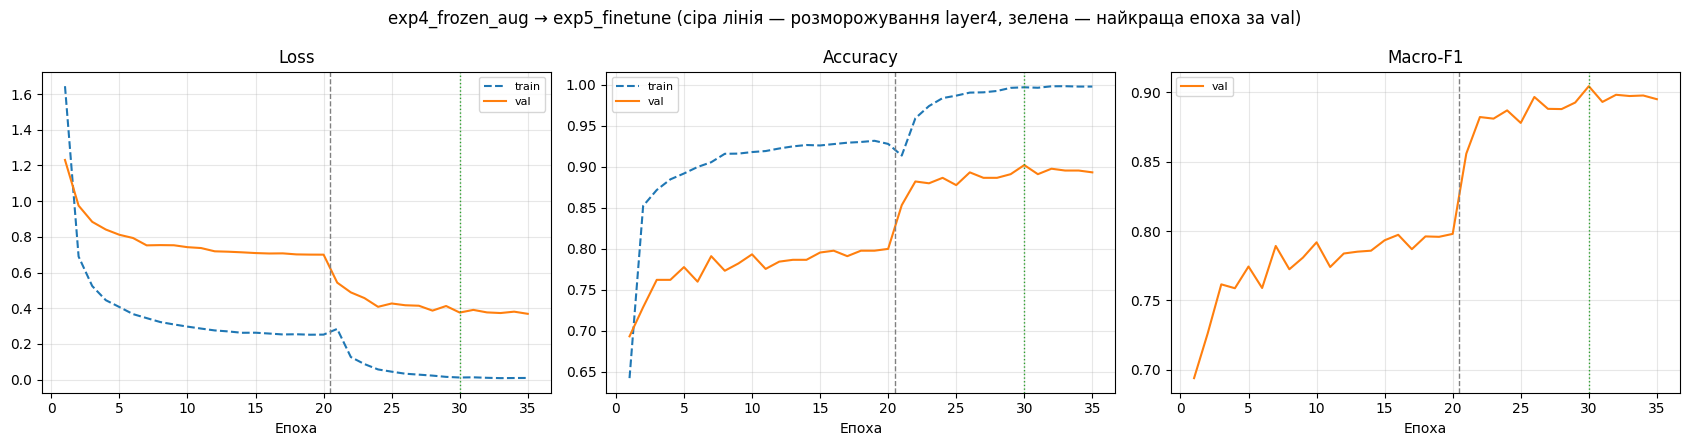

In [11]:
# Криві навчання: перші епохи — стартова модель (exp3/exp4), далі — fine-tuning
h0 = prev_hist[BASE]
both = {k: h0[k] + hist_ft[k] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_f1')}
split_at = len(h0['train_loss'])
ep = range(1, len(both['train_loss']) + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(ep, both['train_loss'], '--', label='train'); axes[0].plot(ep, both['val_loss'], label='val')
axes[1].plot(ep, both['train_acc'], '--', label='train'); axes[1].plot(ep, both['val_acc'], label='val')
axes[2].plot(ep, both['val_f1'], color='tab:orange', label='val')
for ax, t in zip(axes, ('Loss', 'Accuracy', 'Macro-F1')):
    ax.axvline(split_at + 0.5, color='gray', ls='--', lw=1)
    ax.axvline(split_at + hist_ft['best_epoch'], color='tab:green', ls=':', lw=1)
    ax.set_title(t); ax.set_xlabel('Епоха'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle(f'{BASE} → exp5_finetune (сіра лінія — розморожування layer4, зелена — найкраща епоха за val)')
plt.tight_layout()
plt.show()

In [12]:
summary = pd.concat([prev_results.drop(index=BASE), pd.DataFrame(results).T])
summary.to_csv(OUT_DIR / 'results_step5.csv')
summary[['trainable_params', 'best_epoch', 'train_acc', 'val_acc', 'val_f1', 'test_acc', 'test_f1',
         'train-val gap', 'train_time_s']].round(4)

,trainable_params,best_epoch,train_acc,val_acc,val_f1,test_acc,test_f1,train-val gap,train_time_s
exp3_frozen,15390.0,14.0,0.9566,0.8000,0.7992,0.8050,0.8059,0.1566,93.0
exp4_frozen_aug,15390.0,20.0,0.9399,0.8000,0.7979,0.7900,0.7886,0.1399,98.0
exp5_finetune,8409118.0,10.0,0.9998,0.9022,0.9045,0.9033,0.9006,0.0976,105.0


## 7. Метрики для кожного класу (test)

Для кожного класу рахуємо на test (20 зображень на клас):
* **precision** — яка частка зображень, віднесених моделлю до класу, справді йому належить
  (низька precision — модель «стягує» в цей клас чужі зображення);
* **recall** — яка частка зображень класу розпізнана правильно. Це і є **accuracy класу** у звичному розумінні
  (кількість правильних прогнозів серед зображень цього класу);
* **F1** — гармонічне середнє precision і recall;
* **accuracy (one-vs-rest)** — (TP + TN) / N для бінарної задачі «клас vs решта». Вона завжди близька до 1,
  бо TN (зображення інших класів, правильно не віднесені до цього класу) домінують — тож для порівняння класів
  інформативніші precision і recall.

Один тестовий приклад = 0.05 recall класу, тож зміни ±0.05 — це одне зображення.

In [13]:
y_test = LABELS[idx['test']].numpy()


def per_class_metrics(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    tp = np.diag(cm)
    fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    tn = cm.sum() - tp - fp - fn
    out = pd.DataFrame({'precision': p, 'recall (= accuracy класу)': r, 'f1': f,
                        'accuracy (one-vs-rest)': (tp + tn) / cm.sum(), 'support': s}, index=classes)
    out.loc['macro avg'] = out.iloc[:, :4].mean().tolist() + [s.sum()]
    return out


pc = {name: per_class_metrics(y_test, test_preds[name]) for name in (BASE, 'exp5_finetune')}
for name, t in pc.items():
    t.to_csv(OUT_DIR / f'per_class_{name}.csv')

metric_cols = ['precision', 'recall (= accuracy класу)', 'f1', 'accuracy (one-vs-rest)']
per_class = pd.concat({'до (' + BASE + ')': pc[BASE][metric_cols], 'після (exp5)': pc['exp5_finetune'][metric_cols],
                       'Δ': pc['exp5_finetune'][metric_cols] - pc[BASE][metric_cols]}, axis=1)
per_class[('', 'support')] = pc[BASE]['support'].astype(int)
per_class = per_class.sort_values(('Δ', 'f1'))

(per_class.style.format('{:.3f}', subset=per_class.columns[:-1])
 .background_gradient(cmap='RdYlGn', vmin=0.5, vmax=1.0,
                      subset=[c for c in per_class.columns if c[0] != 'Δ' and c[1] in ('precision', 'recall (= accuracy класу)', 'f1')])
 .background_gradient(cmap='RdYlGn', vmin=-0.3, vmax=0.3, subset=[c for c in per_class.columns if c[0] == 'Δ']))

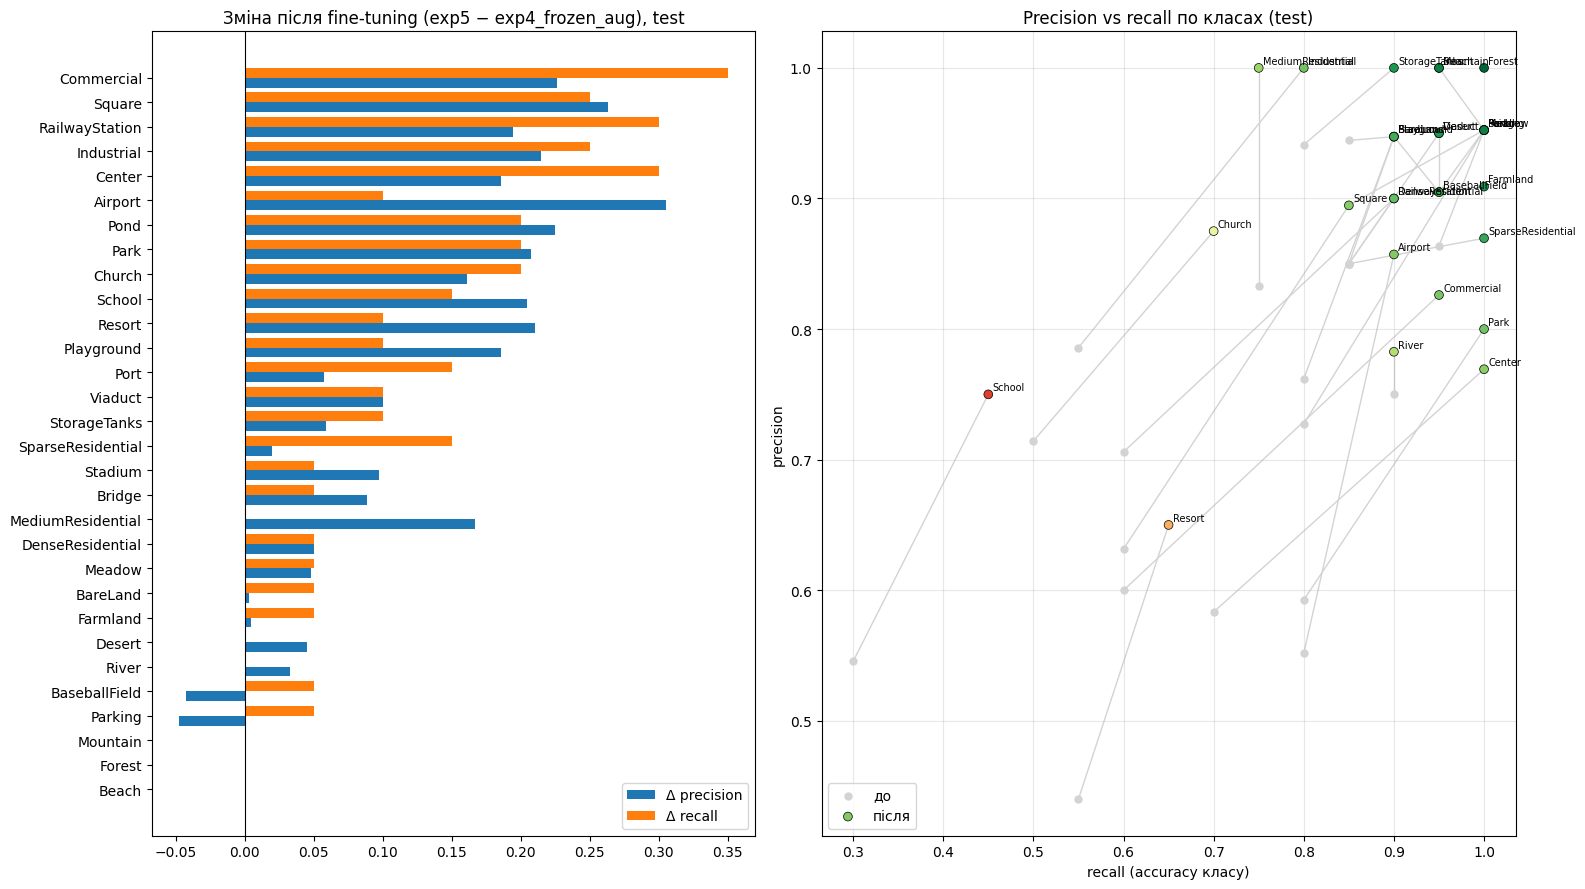

Виправлено помилок exp4_frozen_aug: 76, нових помилок після fine-tuning: 8 (з 600 тестових)


In [14]:
# Зміна precision і recall по класах (відсортовано за ΔF1)
d = per_class['Δ'].drop(index='macro avg')
ypos = np.arange(len(d))
fig, axes = plt.subplots(1, 2, figsize=(16, 9), gridspec_kw={'width_ratios': [1, 1.15]})

axes[0].barh(ypos - 0.2, d['precision'], height=0.4, label='Δ precision', color='tab:blue')
axes[0].barh(ypos + 0.2, d['recall (= accuracy класу)'], height=0.4, label='Δ recall', color='tab:orange')
axes[0].set_yticks(ypos, d.index)
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_title(f'Зміна після fine-tuning (exp5 − {BASE}), test')
axes[0].legend()

# Precision vs recall для кожного класу: сіра точка — до, кольорова — після
before, after = pc[BASE].drop(index='macro avg'), pc['exp5_finetune'].drop(index='macro avg')
r_col = 'recall (= accuracy класу)'
for c in classes:
    axes[1].plot([before.loc[c, r_col], after.loc[c, r_col]], [before.loc[c, 'precision'], after.loc[c, 'precision']],
                 color='lightgray', lw=1, zorder=1)
axes[1].scatter(before[r_col], before['precision'], color='lightgray', s=25, label='до', zorder=2)
axes[1].scatter(after[r_col], after['precision'], c=after['f1'], cmap='RdYlGn', vmin=0.5, vmax=1,
                s=40, edgecolor='black', lw=0.5, label='після', zorder=3)
for c in classes:
    axes[1].annotate(c, (after.loc[c, r_col], after.loc[c, 'precision']), fontsize=7,
                     xytext=(3, 3), textcoords='offset points')
axes[1].set_xlabel('recall (accuracy класу)'); axes[1].set_ylabel('precision')
axes[1].set_title('Precision vs recall по класах (test)')
axes[1].grid(alpha=0.3); axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

fixed = ((test_preds[BASE] != y_test) & (test_preds['exp5_finetune'] == y_test)).sum()
broken = ((test_preds[BASE] == y_test) & (test_preds['exp5_finetune'] != y_test)).sum()
print(f'Виправлено помилок {BASE}: {fixed}, нових помилок після fine-tuning: {broken} (з {len(y_test)} тестових)')

np.savez(OUT_DIR / 'test_preds_step5.npz', y_test=y_test, test_idx=idx['test'], **test_preds)
json.dump(histories, open(OUT_DIR / 'histories_step5.json', 'w'))

## 8. Висновки

_(заповнити після запуску)_

* **До / після:** зміна val і test accuracy та macro-F1 після розморожування `layer4`; на якій епосі fine-tuning
  досягнуто найкращого val-результату.
* **Перенавчання:** тепер навчається ~8.4 млн параметрів замість ~15 тис. — чи виріс `train-val gap`,
  чи почав рости val loss наприкінці донавчання.
* **По класах:** які класи найбільше виграли (за recall / precision), які лишились найслабшими і з якими класами
  їх, імовірно, плутає модель (низька precision одного класу + низький recall іншого часто означають взаємну плутанину,
  напр. `School` ↔ `Commercial`, `Center` ↔ `Square`). Детально — матриці помилок у завданні 8.
* Зміни recall класу на 0.05 — це одне тестове зображення, тож дрібні зміни по окремих класах — шум.